# Exercise 31 – Kernel ridge regression

**Week 6 · Regression**

Kernel ridge regression (KRR) writes the model as a sum over the training points,

$$f(x) = \sum_i \alpha_i\, K(x, x_i), \qquad \boldsymbol\alpha = (K + \lambda I)^{-1}\mathbf y,$$

where the kernel $K(x, x')$ measures the similarity of two inputs. We try

* the polynomial kernel $K = (1 + x x')^n$, equivalent to ridge regression on
  polynomials of degree $n$ (exercise 33), and
* the Gaussian kernel $K = e^{-(x-x')^2/2\sigma^2}$, a sum of bumps centred on the data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.plotting import setup_axes
from comphy.regression import KernelRidge, gaussian_kernel, polynomial_kernel

rng = np.random.default_rng(0)


def compare(f, x_data, y_data, models, title, xlim=(-3, 6), ylim=(-2, 3)):
    xs = np.linspace(*xlim, 400)
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(xs, f(xs), color="black", label="target")
    ax.scatter(x_data, y_data, color="red", zorder=3, label="data")
    for i, model in enumerate(models):
        model.fit(x_data, y_data)
        ax.plot(xs, model.predict(xs), color=f"C{i + 1}", label=model.label())
    setup_axes(ax, xlim=xlim, ylim=ylim, title=title)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()

## Five exact data points

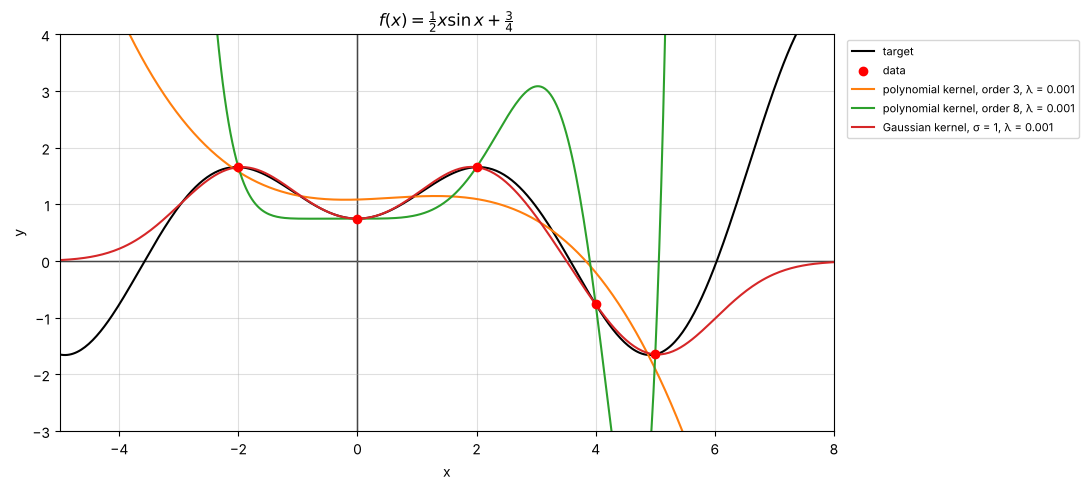

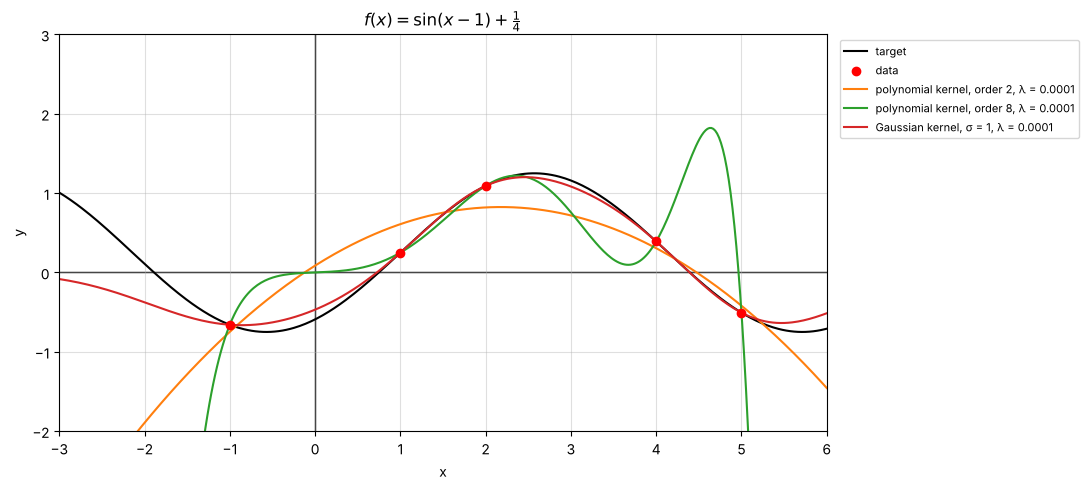

In [2]:
f1 = lambda x: 0.5 * x * np.sin(x) + 0.75
x1 = np.array([-2, 0, 2, 4, 5])
compare(f1, x1, f1(x1),
        [KernelRidge(polynomial_kernel(3), 1e-3), KernelRidge(polynomial_kernel(8), 1e-3),
         KernelRidge(gaussian_kernel(1.0), 1e-3)],
        r"$f(x) = \frac{1}{2}x\sin x + \frac{3}{4}$", xlim=(-5, 8), ylim=(-3, 4))

f2 = lambda x: np.sin(x - 1) + 0.25
x2 = np.array([-1, 1, 2, 4, 5])
compare(f2, x2, f2(x2),
        [KernelRidge(polynomial_kernel(2), 1e-4), KernelRidge(polynomial_kernel(8), 1e-4),
         KernelRidge(gaussian_kernel(1.0), 1e-4)],
        r"$f(x) = \sin(x - 1) + \frac{1}{4}$")

Away from the data the Gaussian-kernel model returns to zero (every term is a
localised bump), while polynomial kernels extrapolate as polynomials.

## Thirty noisy points

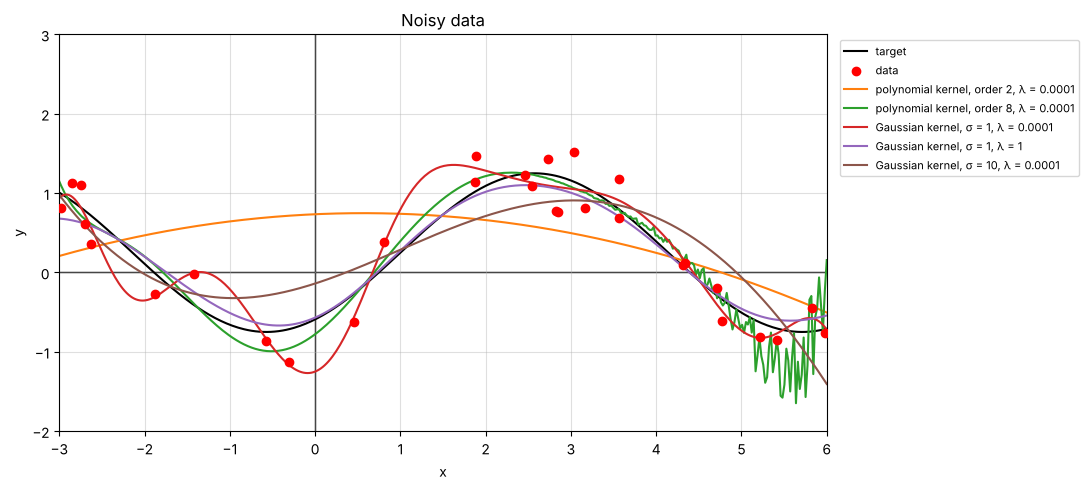

In [3]:
x_noisy = rng.uniform(-3, 6, 30)
y_noisy = f2(x_noisy) + rng.uniform(-0.5, 0.5, 30)
compare(f2, x_noisy, y_noisy,
        [KernelRidge(polynomial_kernel(2), 1e-4), KernelRidge(polynomial_kernel(8), 1e-4),
         KernelRidge(gaussian_kernel(1.0), 1e-4), KernelRidge(gaussian_kernel(1.0), 1.0),
         KernelRidge(gaussian_kernel(10.0), 1e-4)],
        "Noisy data")

The kernel width sets the length scale of the model: $\sigma = 10$ is too
smooth to follow the sine, $\sigma = 1$ follows it, and the regularisation
$\lambda$ controls how much the fit chases the noise ($\lambda = 1$ gives the
smoothest curve close to the target). The order-2 polynomial kernel is far
too simple, and the order-8 kernel becomes numerically ill-conditioned –
note the high-frequency wiggles near $x = 6$, where $(1 + xx')^8$ is huge.